## <div align="center"> Final Project IS388 Data Analysis </div>
#### <div align="center"> Semester Ganjil 2024/2025 </div>
---

### Data Preprocessing 

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

import warnings
import math
from scipy.stats import variation

%matplotlib inline 
warnings.filterwarnings('ignore') 
sns.set_style("darkgrid") 
import sklearn 
from sklearn.metrics import mean_squared_error

In [5]:
data=pd.read_csv("marketing_campaign_dataset.csv")

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Campaign_ID       200000 non-null  int64  
 1   Company           200000 non-null  object 
 2   Campaign_Type     200000 non-null  object 
 3   Target_Audience   200000 non-null  object 
 4   Duration          200000 non-null  object 
 5   Channel_Used      200000 non-null  object 
 6   Conversion_Rate   200000 non-null  float64
 7   Acquisition_Cost  200000 non-null  object 
 8   ROI               200000 non-null  float64
 9   Location          200000 non-null  object 
 10  Language          200000 non-null  object 
 11  Clicks            200000 non-null  int64  
 12  Impressions       200000 non-null  int64  
 13  Engagement_Score  200000 non-null  int64  
 14  Customer_Segment  200000 non-null  object 
 15  Date              200000 non-null  object 
dtypes: float64(2), int64

In [7]:
data.describe()

,Campaign_ID,Conversion_Rate,ROI,Clicks,Impressions,Engagement_Score
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,100000.500000,0.080070,5.002438,549.772030,5507.301520,5.494710
std,57735.171256,0.040602,1.734488,260.019056,2596.864286,2.872581
min,1.000000,0.010000,2.000000,100.000000,1000.000000,1.000000
25%,50000.750000,0.050000,3.500000,325.000000,3266.000000,3.000000
50%,100000.500000,0.080000,5.010000,550.000000,5517.500000,5.000000
75%,150000.250000,0.120000,6.510000,775.000000,7753.000000,8.000000
max,200000.000000,0.150000,8.000000,1000.000000,10000.000000,10.000000


In [8]:
data.head()

,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.04,"$16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.12,"$11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02
2,3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.07,"$10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03
3,4,DataTech Solutions,Display,All Ages,60 days,YouTube,0.11,"$12,724.00",5.55,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04
4,5,NexGen Systems,Email,Men 25-34,15 days,YouTube,0.05,"$16,452.00",6.50,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05


### Data cleaning

In [10]:
#Membuat NaN values 
np.random.seed(0)

nan_indices = np.random.choice(data.index, size=int(0.02* data.size), replace=True) 
nan_columns = np.random.choice(data.columns, size=int(0.02* data.size), replace=True) 


for idx, col in zip(nan_indices, nan_columns): 
    data.at[idx, col] = np.nan 

In [11]:
data_nan = data.isna().sum()

print(data_nan)

#Menampilkan NaN value

Campaign_ID         3908
Company             4040
Campaign_Type       3914
Target_Audience     4068
Duration            4073
Channel_Used        3785
Conversion_Rate     3925
Acquisition_Cost    3941
ROI                 3979
Location            4005
Language            3940
Clicks              3954
Impressions         3981
Engagement_Score    3982
Customer_Segment    3942
Date                3942
dtype: int64


In [12]:
data.shape

(200000, 16)

In [13]:
cleaned_data = data.dropna()

print(cleaned_data.shape)

(145166, 16)


In [14]:
duplicates = data.duplicated().sum()

print(f'Jumlah duplikat: {duplicates}')

Jumlah duplikat: 0


In [15]:
# Hitung jumlah NaN per kolom setelah dibersihkan
nan_after_clean = cleaned_data.isna().sum()

# Hitung jumlah duplikat setelah dibersihkan
duplicates_after_clean = cleaned_data.duplicated().sum()

print(nan_after_clean)
print("duplicates : ", duplicates_after_clean)

Campaign_ID         0
Company             0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Conversion_Rate     0
Acquisition_Cost    0
ROI                 0
Location            0
Language            0
Clicks              0
Impressions         0
Engagement_Score    0
Customer_Segment    0
Date                0
dtype: int64
duplicates :  0


### Encoding

In [17]:
marketing_data = cleaned_data
marketing_data.dtypes


Campaign_ID         float64
Company              object
Campaign_Type        object
Target_Audience      object
Duration             object
Channel_Used         object
Conversion_Rate     float64
Acquisition_Cost     object
ROI                 float64
Location             object
Language             object
Clicks              float64
Impressions         float64
Engagement_Score    float64
Customer_Segment     object
Date                 object
dtype: object

In [18]:
print(marketing_data.isnull().sum())

Campaign_ID         0
Company             0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Conversion_Rate     0
Acquisition_Cost    0
ROI                 0
Location            0
Language            0
Clicks              0
Impressions         0
Engagement_Score    0
Customer_Segment    0
Date                0
dtype: int64


In [19]:
# Cek nilai unik di setiap kolom
encoding = ['Company', 'Campaign_Type', 'Duration', 
                     'Channel_Used', 'Target_Audience', 
                     'Location', 'Language', 
                     'Customer_Segment']

for column in encoding:
    print(f"{column}: {marketing_data[column].unique()}")


Company: ['Innovate Industries' 'NexGen Systems' 'DataTech Solutions'
 'Alpha Innovations' 'TechCorp']
Campaign_Type: ['Email' 'Display' 'Search' 'Social Media' 'Influencer']
Duration: ['30 days' '60 days' '15 days' '45 days']
Channel_Used: ['Google Ads' 'YouTube' 'Instagram' 'Website' 'Facebook' 'Email']
Target_Audience: ['Men 18-24' 'Women 35-44' 'All Ages' 'Men 25-34' 'Women 25-34']
Location: ['Chicago' 'New York' 'Miami' 'Los Angeles' 'Houston']
Language: ['Spanish' 'German' 'Mandarin' 'English' 'French']
Customer_Segment: ['Health & Wellness' 'Fashionistas' 'Foodies' 'Tech Enthusiasts'
 'Outdoor Adventurers']


In [20]:
company_mapping = {'Innovate Industries': 0, 'DataTech Solutions': 1, 'Alpha Innovations': 2, 'TechCorp': 3, 'NexGen Systems': 4}
campaign_type_mapping = {'Email': 0, 'Display': 1, 'Social Media': 2, 'Influencer': 3, 'Search': 4}
duration_mapping = {'15 days': 0, '30 days': 1, '45 days': 2, '60 days': 3}
channel_used_mapping = {'Google Ads': 0, 'Instagram': 1, 'Facebook': 2, 'Website': 3, 'Email': 4, 'YouTube': 5}
target_audience_mapping = {'Men 18-24': 0, 'All Ages': 1, 'Women 35-44': 2, 'Men 25-34': 3, 'Women 25-34': 4}
location_mapping = {'Chicago': 0, 'New York': 1, 'Houston': 2, 'Miami': 3, 'Los Angeles': 4}
language_mapping = {'Spanish': 0, 'German': 1, 'Mandarin': 2, 'English': 3, 'French': 4}
customer_segment_mapping = {'Health & Wellness': 0, 'Foodies': 1, 'Tech Enthusiasts': 2, 'Outdoor Adventurers': 3, 'Fashionistas': 4}


In [21]:
marketing_data['Company'] = marketing_data['Company'].map(company_mapping).fillna(-1).astype(int)
marketing_data['Campaign_Type'] = marketing_data['Campaign_Type'].map(campaign_type_mapping).fillna(-1).astype(int)
marketing_data['Duration'] = marketing_data['Duration'].map(duration_mapping).fillna(-1).astype(int)
marketing_data['Channel_Used'] = marketing_data['Channel_Used'].map(channel_used_mapping).fillna(-1).astype(int)
marketing_data['Target_Audience'] = marketing_data['Target_Audience'].map(target_audience_mapping).fillna(-1).astype(int)
marketing_data['Location'] = marketing_data['Location'].map(location_mapping).fillna(-1).astype(int)
marketing_data['Language'] = marketing_data['Language'].map(language_mapping).fillna(-1).astype(int)
marketing_data['Customer_Segment'] = marketing_data['Customer_Segment'].map(customer_segment_mapping).fillna(-1).astype(int)
marketing_data['Campaign_ID'] = marketing_data['Campaign_ID'].astype(str)
marketing_data['Acquisition_Cost'] = marketing_data['Acquisition_Cost'].str.replace('$', '', regex=False)
marketing_data['Acquisition_Cost'] = marketing_data['Acquisition_Cost'].str.replace(',', '', regex=False)
marketing_data['Acquisition_Cost'] = marketing_data['Acquisition_Cost'].astype(float)
marketing_data['Date'] = pd.to_datetime(marketing_data['Date'], format='%Y-%m-%d')


In [22]:
# Cek hasil konversi
print(marketing_data.dtypes)

Campaign_ID                 object
Company                      int32
Campaign_Type                int32
Target_Audience              int32
Duration                     int32
Channel_Used                 int32
Conversion_Rate            float64
Acquisition_Cost           float64
ROI                        float64
Location                     int32
Language                     int32
Clicks                     float64
Impressions                float64
Engagement_Score           float64
Customer_Segment             int32
Date                datetime64[ns]
dtype: object


In [23]:
# Mengganti NaN dengan nilai yang sesuai (misalnya 'Unknown' untuk kategori nominal)
marketing_data.isna().sum()

Campaign_ID         0
Company             0
Campaign_Type       0
Target_Audience     0
Duration            0
Channel_Used        0
Conversion_Rate     0
Acquisition_Cost    0
ROI                 0
Location            0
Language            0
Clicks              0
Impressions         0
Engagement_Score    0
Customer_Segment    0
Date                0
dtype: int64

In [24]:
marketing_data.dtypes

Campaign_ID                 object
Company                      int32
Campaign_Type                int32
Target_Audience              int32
Duration                     int32
Channel_Used                 int32
Conversion_Rate            float64
Acquisition_Cost           float64
ROI                        float64
Location                     int32
Language                     int32
Clicks                     float64
Impressions                float64
Engagement_Score           float64
Customer_Segment             int32
Date                datetime64[ns]
dtype: object

### Check Correlation

In [26]:
df = marketing_data[['Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 
                  'Conversion_Rate', 'Acquisition_Cost', 'ROI', 'Clicks']]

In [27]:
correlation_matrix = df.corr()

In [28]:
correlation_matrix

,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Clicks
Campaign_Type,1.000000,-0.000338,0.004363,0.000977,0.002022,0.001867,0.005609,-0.003349
Target_Audience,-0.000338,1.000000,-0.000726,0.001818,-0.002148,-0.001623,0.003287,0.002457
Duration,0.004363,-0.000726,1.000000,0.002689,0.001542,0.000973,0.001363,-0.000521
Channel_Used,0.000977,0.001818,0.002689,1.000000,0.000415,-0.002699,-0.001970,0.003171
Conversion_Rate,0.002022,-0.002148,0.001542,0.000415,1.000000,-0.001442,-0.001584,0.000899
Acquisition_Cost,0.001867,-0.001623,0.000973,-0.002699,-0.001442,1.000000,0.003673,-0.001013
ROI,0.005609,0.003287,0.001363,-0.001970,-0.001584,0.003673,1.000000,-0.002118
Clicks,-0.003349,0.002457,-0.000521,0.003171,0.000899,-0.001013,-0.002118,1.000000


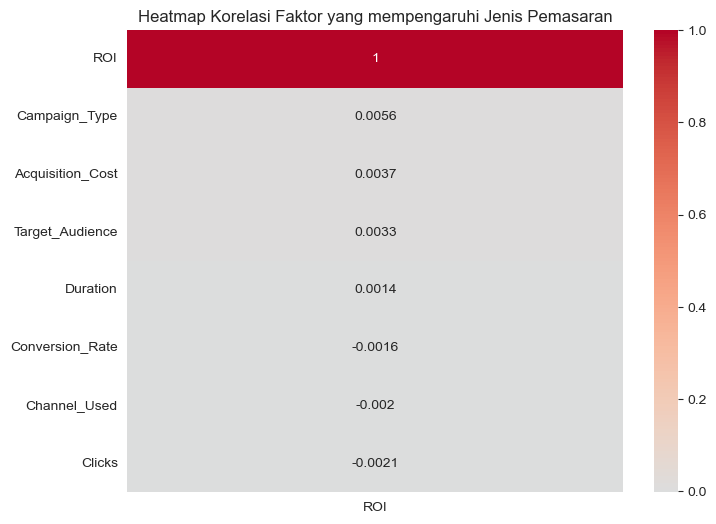

In [117]:
weather_factors_coor = correlation_matrix['ROI'].sort_values(ascending=False)
weather_factors_coor 
plt.figure(figsize=(8, 6))
sns.heatmap(weather_factors_coor.to_frame(), annot=True, cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi Faktor yang mempengaruhi Jenis Pemasaran')
plt.show()

In [30]:
marketing_data.drop('Date', axis=1, inplace=True)  

### Data Visualization

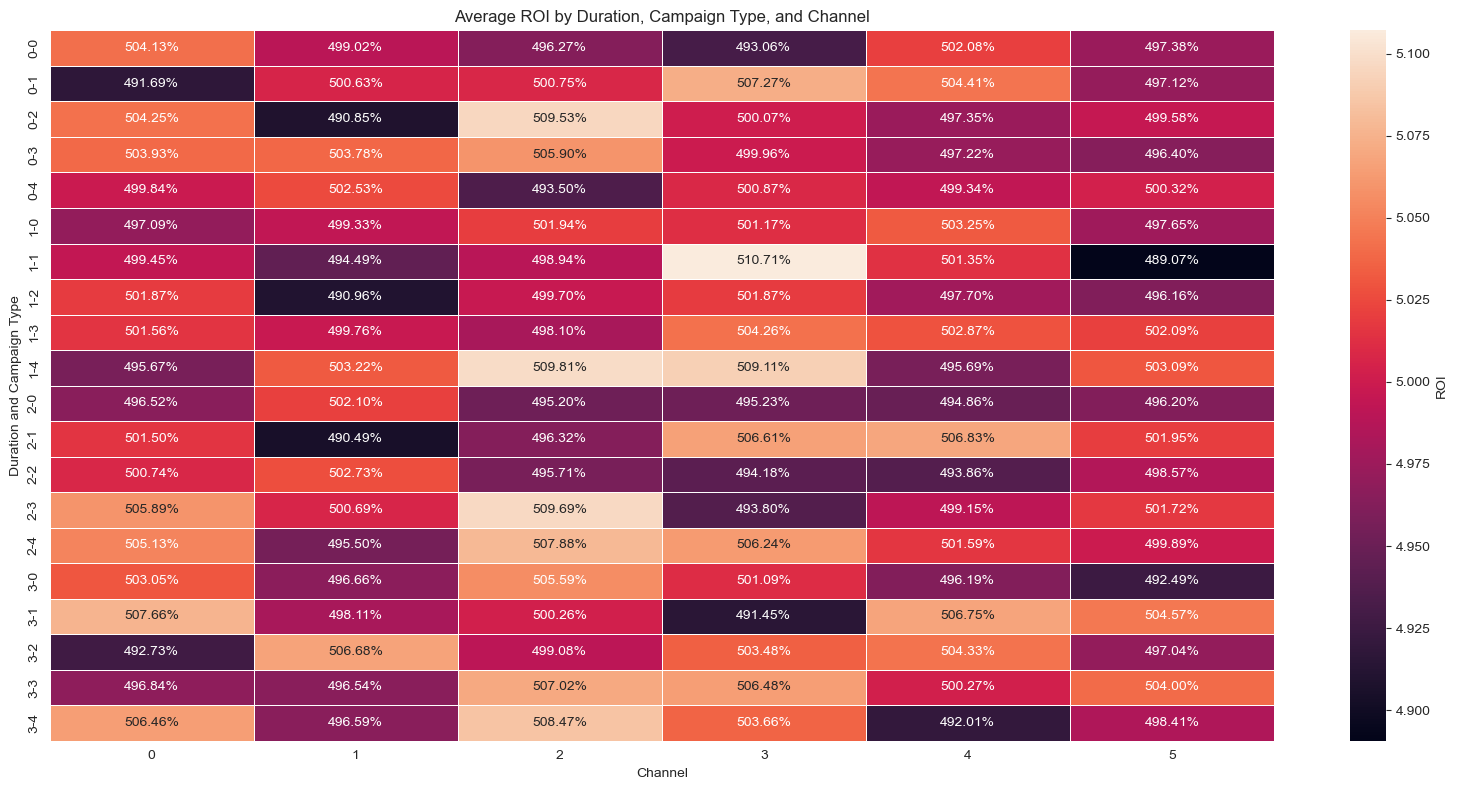

In [32]:
avg_ROI = marketing_data.groupby(['Duration', 'Campaign_Type', 'Channel_Used'])['ROI'].mean().unstack()
plt.figure(figsize=(16, 8))
sns.heatmap(avg_ROI, annot=True, fmt='.2%', linewidths=0.5, cbar_kws={'label': 'ROI'})
plt.title('Average ROI by Duration, Campaign Type, and Channel')
plt.xlabel('Channel')
plt.xticks(rotation=0)
plt.ylabel('Duration and Campaign Type')

plt.savefig('result.png')

plt.tight_layout()
plt.show()


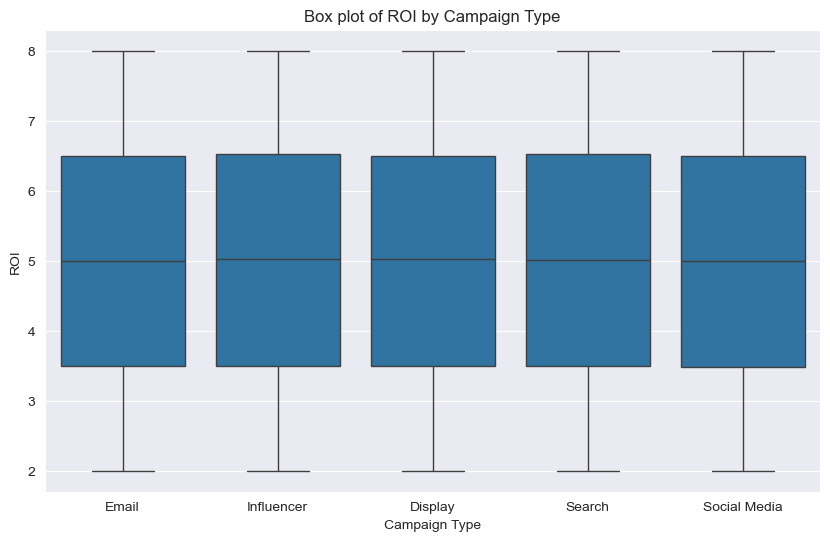

In [121]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=data, x='Campaign_Type', y='ROI')
plt.title('Box plot of ROI by Campaign Type')
plt.xlabel('Campaign Type')
plt.ylabel('ROI')
plt.show()

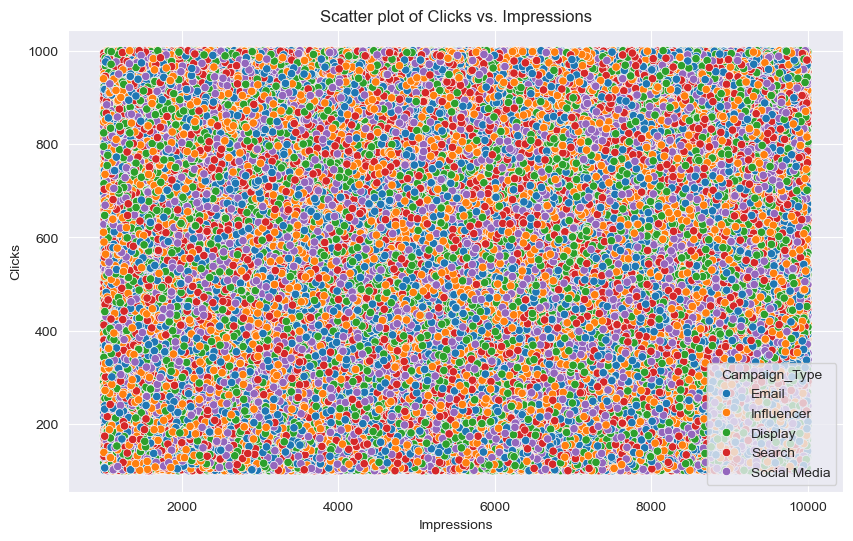

In [125]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=data, x='Impressions', y='Clicks', hue='Campaign_Type')
plt.title('Scatter plot of Clicks vs. Impressions')
plt.xlabel('Impressions')
plt.ylabel('Clicks')
plt.show()

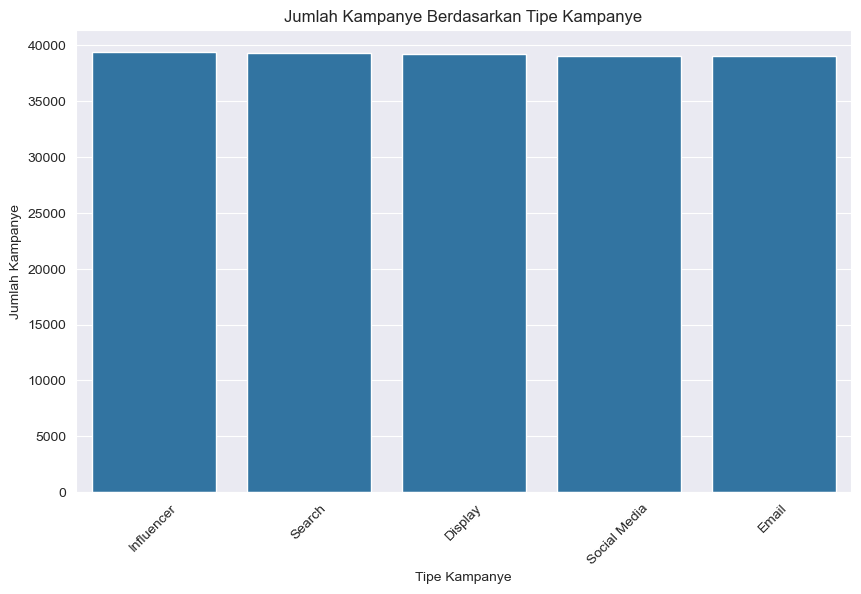

In [35]:
plt.figure(figsize=(10, 6))
sns.countplot(data=data, x='Campaign_Type', order=data['Campaign_Type'].value_counts().index)
plt.title('Jumlah Kampanye Berdasarkan Tipe Kampanye')
plt.xlabel('Tipe Kampanye')
plt.ylabel('Jumlah Kampanye')
plt.xticks(rotation=45)
plt.show()

Boxplot ini menggambarkan jumlah kampanye berdasarkan tipe kampanye, dengan judul "Jumlah Kampanye Berdasarkan Tipe Kampanye". Pada sumbu vertikal (Y), jumlah kampanye berkisar dari 0 hingga 40.000, sementara sumbu horizontal (X) menunjukkan berbagai tipe kampanye, yaitu Influencer, Search, Display, Social Media, dan Email. Setiap batang pada boxplot mewakili jumlah kampanye untuk masing-masing tipe, dan terlihat bahwa semua tipe kampanye memiliki jumlah yang hampir sama, sekitar 40.000.

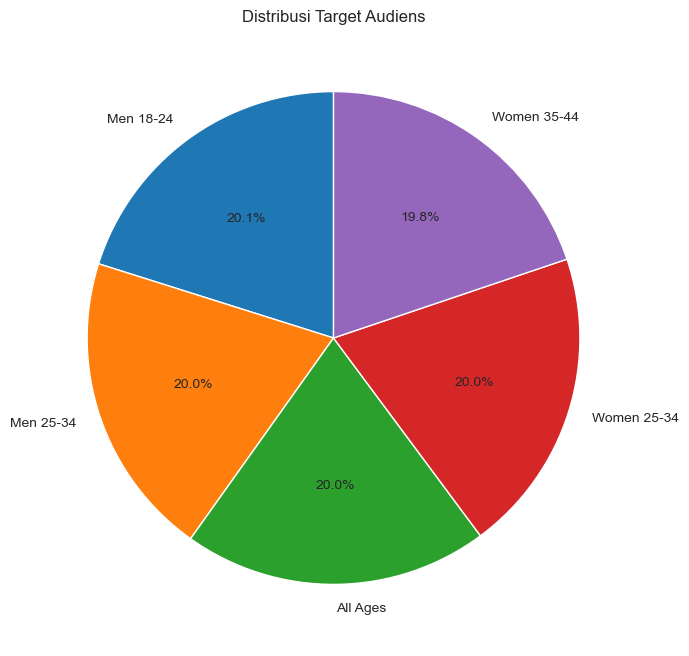

In [37]:
plt.figure(figsize=(8, 8))
data['Target_Audience'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90)
plt.title('Distribusi Target Audiens')
plt.ylabel('')
plt.show()

Pie chart ini menggambarkan distribusi dari target audiens yang menerima kampanye marketing. Dapat dilihat bahwa distribusi data target audiens cukup merata di antara berbagai kelompok usia dan jenis kelamin. Kelompok terbesar adalah pria berusia 18-24 tahun, yang mencakup 20,1% dari total audiens, diikuti oleh wanita berusia 35-44 tahun dengan 19,8%. Selain itu, pria berusia 25-34 tahun, wanita berusia 25-34 tahun, dan kelompok usia lainnya masing-masing menyumbang 20% dari total audiens. Terakhir, kategori "All Ages" juga mencakup 20% dari total, menunjukkan bahwa kampanye ini dirancang untuk menjangkau berbagai demografi. Secara keseluruhan, pie chart ini menunjukkan bahwa kampanye marketing memiliki pendekatan yang inklusif, mencakup berbagai segmen audiens dengan proporsi yang seimbang.

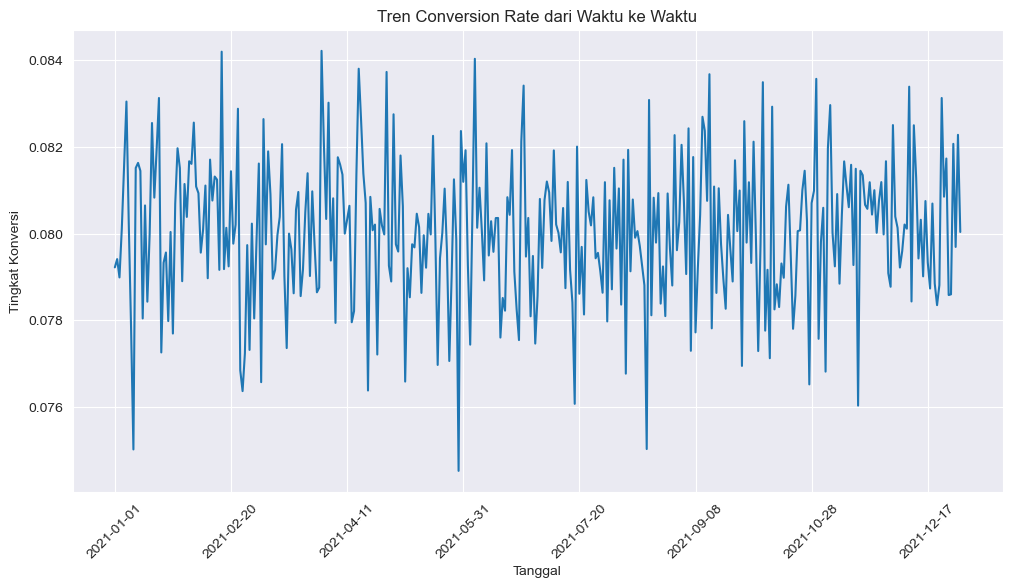

In [39]:
plt.figure(figsize=(12, 6))
data.groupby('Date')['Conversion_Rate'].mean().plot.line()
plt.title('Tren Conversion Rate dari Waktu ke Waktu')
plt.xlabel('Tanggal')
plt.ylabel('Tingkat Konversi')
plt.xticks(rotation=45)
plt.show()

Line chart ini menggambarkan tren tingkat konversi dari waktu ke waktu, dengan sumbu horizontal (X) menunjukkan tanggal dan sumbu vertikal (Y) menunjukkan tingkat konversi. Line chart ini fokus pada perubahan tingkat konversi sepanjang periode yang ditampilkan, yaitu dari awal hingga akhir tahun 2021. Tingkat konversi berkisar antara 0,076 hingga 0,084, mencerminkan persentase pengunjung yang melakukan tindakan yang diinginkan, seperti pembelian atau pendaftaran.

In [41]:
selected_columns = ['Date','Conversion_Rate','Campaign_Type','ROI']
data_selected = data[selected_columns]
print(data_selected.head())
print(data_selected.info())
print(data_selected.describe())

         Date  Conversion_Rate Campaign_Type   ROI
0  2021-01-01             0.04         Email  6.29
1  2021-01-02             0.12         Email  5.61
2  2021-01-03             0.07    Influencer  7.18
3  2021-01-04             0.11       Display  5.55
4  2021-01-05             0.05         Email  6.50
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 4 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   Date             196058 non-null  object 
 1   Conversion_Rate  196075 non-null  float64
 2   Campaign_Type    196086 non-null  object 
 3   ROI              196021 non-null  float64
dtypes: float64(2), object(2)
memory usage: 6.1+ MB
None
       Conversion_Rate            ROI
count    196075.000000  196021.000000
mean          0.080075       5.002043
std           0.040600       1.734293
min           0.010000       2.000000
25%           0.050000       3.500000
50%           0.0

### Modeling

In [43]:
marketing_data.head()

,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment
0,1.0,0,0,0,1,0,0.04,16174.0,6.29,0,0,506.0,1922.0,6.0,0
1,2.0,4,0,2,3,0,0.12,11566.0,5.61,1,1,116.0,7523.0,7.0,4
3,4.0,1,1,1,3,5,0.11,12724.0,5.55,3,2,217.0,1820.0,7.0,0
5,6.0,1,1,1,0,1,0.07,9716.0,4.36,1,1,100.0,1643.0,1.0,1
6,7.0,4,0,2,3,3,0.13,11067.0,2.86,4,0,817.0,8749.0,10.0,2


In [44]:
mdf = marketing_data[["Campaign_Type", "Duration", "Channel_Used", "Conversion_Rate", "Acquisition_Cost", "ROI", "Clicks"]]

In [45]:
X = mdf.drop(columns=["ROI"])
y = mdf["ROI"]

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [47]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [48]:
print(f"Training set size after scaling: {X_train_scaled.shape}")
print(f"Testing set size after scaling: {X_test_scaled.shape}")

Training set size after scaling: (116132, 6)
Testing set size after scaling: (29034, 6)


In [49]:
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

LinearRegression()

In [50]:
pr = PolynomialFeatures(degree=3)
X_train_poly = pr.fit_transform(X_train_scaled)
X_test_poly = pr.transform(X_test_scaled)

In [51]:
lr_poly = LinearRegression()
lr_poly.fit(X_train_poly, y_train)

LinearRegression()

In [52]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Prediksi untuk Linear Regression
linear_predictions = lr.predict(X_test_scaled)

# Prediksi untuk Polynomial Regression
polynomial_predictions = lr_poly.predict(X_test_poly)

# Evaluasi Linear Regression
mae_linear = mean_absolute_error(y_test, linear_predictions)
mse_linear = mean_squared_error(y_test, linear_predictions)
r2_linear = r2_score(y_test, linear_predictions)

# Evaluasi Polynomial Regression
mae_poly = mean_absolute_error(y_test, polynomial_predictions)
mse_poly = mean_squared_error(y_test, polynomial_predictions)
r2_poly = r2_score(y_test, polynomial_predictions)

# Menyusun hasil evaluasi
evaluation = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression'],
    'MAE': [mae_linear, mae_poly],
    'MSE': [mse_linear, mse_poly],
    'R-Square': [r2_linear, r2_poly]
})

print(evaluation)

                   Model       MAE       MSE  R-Square
0      Linear Regression  1.507909  3.024618  0.000031
1  Polynomial Regression  1.508330  3.026169 -0.000482


In [53]:
new_data = pd.DataFrame({
    "Campaign_Type": ["Email"],
    "Duration": [1],
    "Channel_Used": ["Google Ads"],
    "Conversion_Rate": [0.06],
    "Acquisition_Cost": [16170.0],
    "Clicks": [120]
})

In [54]:
new_data_encoded = pd.get_dummies(new_data, drop_first=True)

In [55]:
missing_cols = set(X) - set(new_data_encoded.columns)
for col in missing_cols:
    new_data_encoded[col] = 0

In [56]:
new_data_encoded = new_data_encoded[X.columns]

In [57]:
new_data_scaled = scaler.transform(new_data_encoded)

In [58]:
prediction_lr = lr.predict(new_data_scaled)
prediction_poly = lr_poly.predict(pr.transform(new_data_scaled))

In [59]:
print("Prediksi ROI (Linear Regression):", prediction_lr)
print("Prediksi ROI (Polynomial Regression):", prediction_poly)

Prediksi ROI (Linear Regression): [5.00699316]
Prediksi ROI (Polynomial Regression): [5.03983307]
